# Predicting Loan Default
**CECS 456 Final Project · Phu Quach, Om Patel and David Ramos · Fall 2026**

This notebook follows the plan in our proposal:

1. Load the data 
2. Exploratory Data Analysis
3. Clean the data
4. Split into training and test sets
5. Set up preprocessing
6. Tune the models
7. Compare the models with cross-validation
8. Ablations (remove some features and retrain)
9. Final test results
10. What the model learned
11. Errors by age group and by renters vs. non-renters
12. Predict a new application
13. Summary and limitations

In [128]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV, cross_validate
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.inspection import permutation_importance
from sklearn.metrics import (average_precision_score, roc_auc_score, accuracy_score, precision_score,
                             recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay,
                             RocCurveDisplay, PrecisionRecallDisplay)
from sklearn.base import clone
from scipy.stats import loguniform, randint

## 1. Load the data

We taking the dataset from *Loan Approval Prediction Dataset-2.zip* on Canvas. 

In [129]:
df = pd.read_csv("credit_risk_dataset 2.csv")
print(df.shape)
df.head(10)

(32581, 12)


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4
5,21,9900,OWN,2.0,VENTURE,A,2500,7.14,1,0.25,N,2
6,26,77100,RENT,8.0,EDUCATION,B,35000,12.42,1,0.45,N,3
7,24,78956,RENT,5.0,MEDICAL,B,35000,11.11,1,0.44,N,4
8,24,83000,RENT,8.0,PERSONAL,A,35000,8.90,1,0.42,N,2
9,21,10000,OWN,6.0,VENTURE,D,1600,14.74,1,0.16,N,3


In [130]:
df.dtypes

person_age                      int64
person_income                   int64
person_home_ownership             str
person_emp_length             float64
loan_intent                       str
loan_grade                        str
loan_amnt                       int64
loan_int_rate                 float64
loan_status                     int64
loan_percent_income           float64
cb_person_default_on_file         str
cb_person_cred_hist_length      int64
dtype: object

In [131]:
num_cols = ["person_age", "person_income", "person_emp_length", "loan_amnt",
            "loan_int_rate", "loan_percent_income", "cb_person_cred_hist_length"]
cat_cols = ["person_home_ownership", "loan_intent", "loan_grade", "cb_person_default_on_file"]

print(len(num_cols), "numeric features")
print(len(cat_cols), "categorical features")
print("target: loan_status")

7 numeric features
4 categorical features
target: loan_status


In [132]:
grade_table = df.groupby("loan_grade")["loan_status"].agg(["count", "mean"])
grade_table["mean"] = (grade_table["mean"] * 100).round(1)
grade_table.columns = ["loans", "% with loan_status = 1"]
grade_table

,loans,% with loan_status = 1
loan_grade,,
A,10777,10.0
B,10451,16.3
C,6458,20.7
D,3626,59.0
E,964,64.4
F,241,70.5
G,64,98.4


## 2. Explore the data

### a. Class balance

loan_status
0    25473
1     7108
Name: count, dtype: int64

loan_status
0    78.2
1    21.8
Name: count, dtype: float64


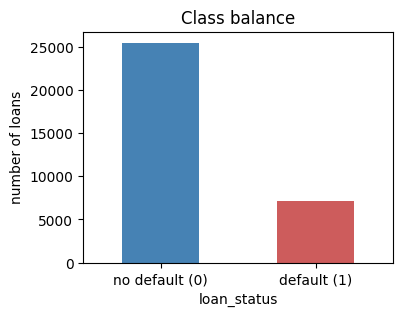

In [133]:
counts = df["loan_status"].value_counts()
print(counts)
print()
print((counts / len(df) * 100).round(1))

counts.plot.bar(color=["steelblue", "indianred"], figsize=(4, 3))
plt.xticks([0, 1], ["no default (0)", "default (1)"], rotation=0)
plt.ylabel("number of loans")
plt.title("Class balance")
plt.show()

Accoding to our investigation, about 78% of loans are 0 (no default) and 22% are 1 (default). Because of this imbalance, accuracy is misleading: a model that always says "no default" would already be 78% accurate.

### b. Missing values

In [134]:
missing = df.isna().sum()
missing_pct = (missing / len(df) * 100).round(1)
pd.DataFrame({"missing": missing, "percent": missing_pct})[missing > 0]

,missing,percent
person_emp_length,895,2.7
loan_int_rate,3116,9.6


Interest rate is missing for about 10% of loans and employment length for about 3%. We will fill them with the median from the training data and add a column that marks which values were missing.

### c. Overall and Checking Outliers

In [135]:
display(df.describe().round(2))

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.00,32581.00,31686.00,32581.00,29465.00,32581.00,32581.00,32581.00
mean,27.73,66074.85,4.79,9589.37,11.01,0.22,0.17,5.80
std,6.35,61983.12,4.14,6322.09,3.24,0.41,0.11,4.06
min,20.00,4000.00,0.00,500.00,5.42,0.00,0.00,2.00
25%,23.00,38500.00,2.00,5000.00,7.90,0.00,0.09,3.00
50%,26.00,55000.00,4.00,8000.00,10.99,0.00,0.15,4.00
75%,30.00,79200.00,7.00,12200.00,13.47,0.00,0.23,8.00
max,144.00,6000000.00,123.00,35000.00,23.22,1.00,0.83,30.00


In [136]:
print("duplicate rows:", df.duplicated().sum())
print("ages over 100:", sorted(df.loc[df["person_age"] > 100, "person_age"]))
print("employment length:", sorted(df.loc[df["person_emp_length"] > 60, "person_emp_length"]))
print("median income:", df["person_income"].median())
print("max income:", df["person_income"].max())

duplicate rows: 165
ages over 100: [123, 123, 144, 144, 144]
employment length: [123.0, 123.0]
median income: 55000.0
max income: 6000000


We find out that some values are impossible such as ages of 123 and 144, and 123 years of employment. We will remove those rows. Income is very skewed (median $55,000, max $6 million), so we will use the log of income instead.

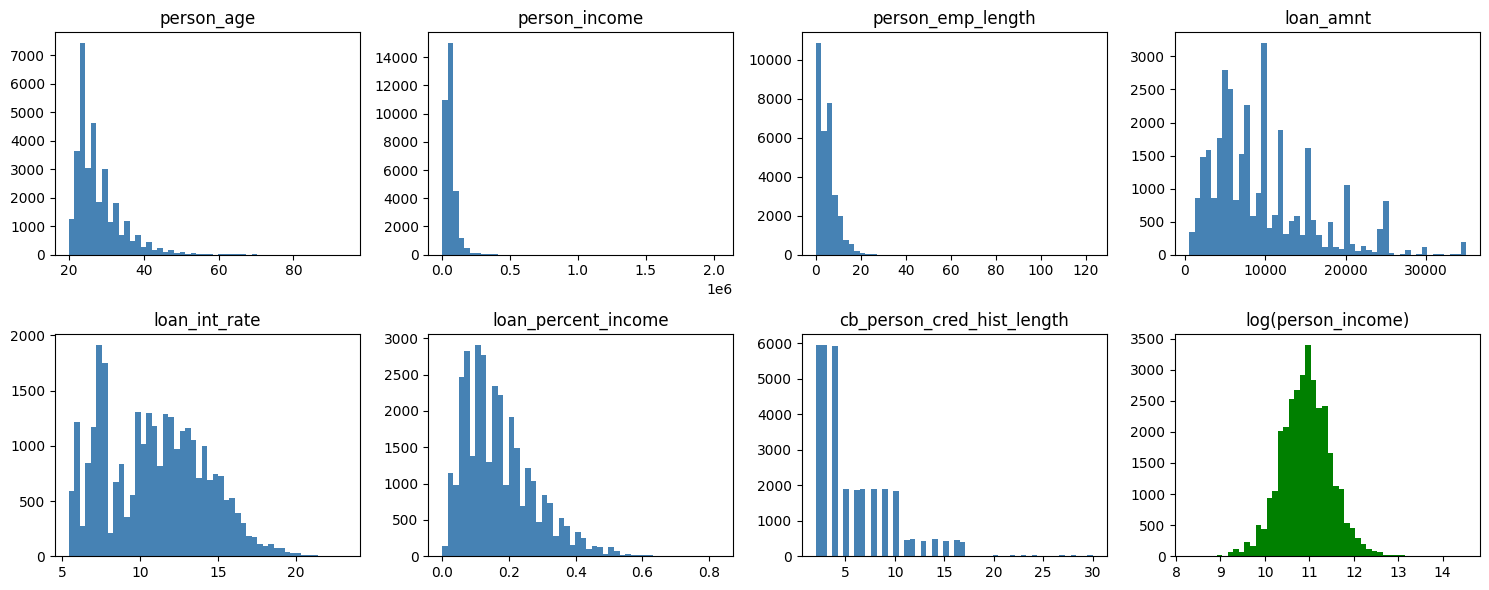

In [137]:
fig, axes = plt.subplots(2, 4, figsize=(15, 6))
no_outliers = df[df["person_age"] <= 100]

for ax, col in zip(axes.flat, num_cols):
    ax.hist(no_outliers[col].dropna(), bins=50, color="steelblue")
    ax.set_title(col)

axes.flat[7].hist(np.log(no_outliers["person_income"]), bins=50, color="green")
axes.flat[7].set_title("log(person_income)")
plt.tight_layout()
plt.show()

### Default rate by group

Default rates change a lot with home ownership, loan purpose, and past defaults, so these columns should help the models.

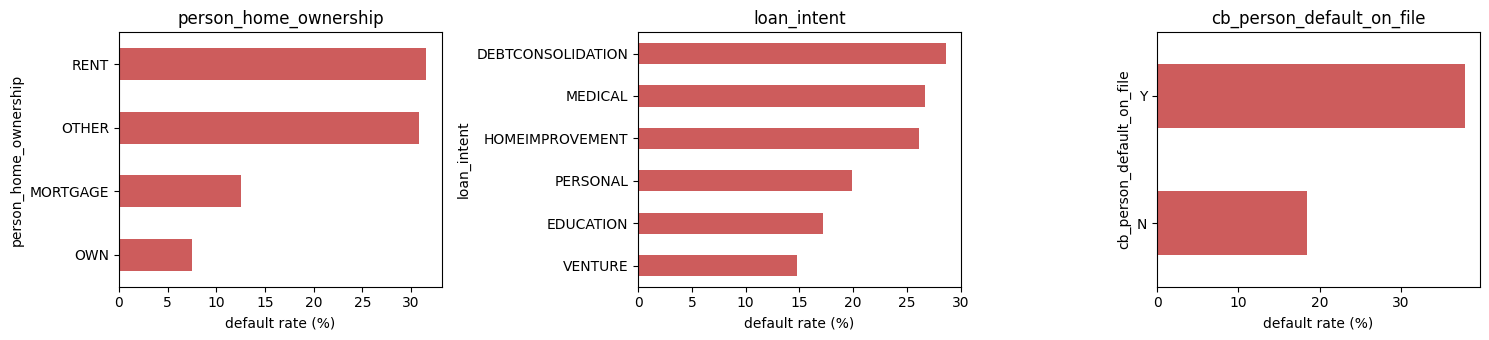

In [138]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, col in zip(axes, ["person_home_ownership", "loan_intent", "cb_person_default_on_file"]):
    rate = df.groupby(col)["loan_status"].mean().sort_values() * 100
    rate.plot.barh(ax=ax, color="indianred")
    ax.set_xlabel("default rate (%)")
    ax.set_title(col)
plt.tight_layout()
plt.show()

## 3. Clean the data

We clean the data before splitting it, so that a duplicate loan cannot end up in both the training set and the test set.

1. Remove duplicate rows
2. Remove impossible ages
3. Remove impossible employment lengths : 2 applicants aged 21 and 22 are listed with 123 years of work experience. We remove any row where the years worked is more than the person's age minus 14
4. Use log(income) instead of income: Income is very skewed: most people earn around $55,000, but a few earn up to $6 million. Taking the log pulls these extreme values closer to the rest, which helps the models that measure distances or fit weights (logistic regression, Naive Bayes, k-NN, SVM, MLP). Tree models are not affected, because the log keeps incomes in the same order.

Using the log before the split is safe. It is a simple math formula applied to each row on its own, so nothing is learned from the other rows or from the test set.

In [139]:
data = df.drop_duplicates()
data = data[data["person_age"] <= 100]
data = data[~(data["person_emp_length"] > data["person_age"] - 14)]   # rows with missing employment length are kept

data["log_income"] = np.log(data["person_income"])
data = data.drop(columns="person_income")
num_cols = ["log_income" if c == "person_income" else c for c in num_cols]

print("rows before:", len(df))
print("rows after: ", len(data))
print("default rate after cleaning:", round(data["loan_status"].mean() * 100, 1), "%")

rows before: 32581
rows after:  32409
default rate after cleaning: 21.9 %


## 4. Split into training and test sets

We keep 80% of the loans for training and set aside 20% as a test set. stratify=y makes sure both parts have the same share of defaults.

In [140]:
X = data.drop(columns="loan_status")
y = data["loan_status"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

print("training set:", len(X_train), "loans,", round(y_train.mean() * 100, 1), "% default")
print("test set:    ", len(X_test), "loans,", round(y_test.mean() * 100, 1), "% default")

training set: 25927 loans, 21.9 % default
test set:     6482 loans, 21.9 % default
